# Lab 2.3: Gates as Memory Engineering — LSTM from scratch, on a task that was supposed to kill the RNN

**Language-model internals series.** [Lab 2.2](/posts/ml/labs/2026-10-27-lab-2-2-language-model-without-attention/) measured the diagnosis instead of reciting it: on a trained char-RNN, the forward echo of a character and the backward BPTT blame both halve every ~2.3 steps (per-step retention 0.74), because the transported term per step is (roughly) $W_{hh}^{\top}\mathrm{diag}(1-h^2)$ — every step multiplies your memory by something whose average magnitude is far below 1.

The LSTM ([Hochreiter & Schmidhuber, 1997](https://www.mitpressjournals.org/doi/10.1162/neco.1997.9.8.1735)) changes *only the transport layer*: a separate **cell state** $c_t$ carried **additively**, $c_t = f_t \odot c_{t-1} + i_t \odot g_t$, whose key derivative is

$$\frac{\partial c_t}{\partial c_{t-1}} = \mathrm{diag}(f_t) \qquad \text{— elementwise, no dense } W \text{ in between.}$$

Forget gate $f_t$ is a *learned per-channel scalar throttle*, and its default can be "stay open". Memory transport becomes a product of near-1 scalars on chosen channels.

This lab planned to be a clean execution: "copy task, RNN bleeds at G=60, LSTM doesn't, good night." It turned into messier and better science — you will watch, with numbers:

1. build the LSTM cell + forward/backward from scratch, FD ritual as always,
2. run the copy task at widening gaps and discover that **both** of our priors were wrong (the RNN survives where it "should" die, and the LSTM *also* fails — for a subtler reason than memory),
3. find the actual cliff, and what the literature's real tricks (forget-bias, curriculum) each contribute — measured, in our own pan,
4. look inside the winning model's gates at work (memory channels holding the gap),
5. re-measure Lab 2.2's decay curves through the cell state, and close with a nuance about why Adam let the RNN over-perform in the first place.

## 0. The cell, precisely

Per time step ($[\cdot;\cdot]$ = concatenation, one wide matmul over $[x_t; h_{t-1}]$):

$$\begin{aligned}
f_t &= \sigma(W_f [x_t; h_{t-1}] + b_f) && \text{forget — the retention throttle}\\
i_t &= \sigma(W_i [x_t; h_{t-1}] + b_i) && \text{input — the write enable}\\
o_t &= \sigma(W_o [x_t; h_{t-1}] + b_o) && \text{output — the read enable}\\
g_t &= \tanh(W_g [x_t; h_{t-1}] + b_g) && \text{candidate contents}\\
c_t &= f_t \odot c_{t-1} + i_t \odot g_t && \text{cell state: additive carry}\\
h_t &= o_t \odot \tanh(c_t) && \text{exposed state}
\end{aligned}$$

Backward book-keeping quadruples, but there is **one derivative that matters more than all others**: in the chain rule for $c$, the $f_t \odot c_{t-1}$ term contributes $\partial c_t / \partial c_{t-1} = \mathrm{diag}(f_t)$. $k$ steps of $f \approx 1$ transports $c$ (and blame through $c$) nearly unchanged — the "constant error carousel" the 1997 paper was built around. Everything else (embedding, softmax head, Adam, clipping) is verbatim Lab 2.2.

## 1. The copy task

Alphabet: 8 `key` symbols (ids 0–7), `blank` = 8, `mark` = 9. One training sequence:

```
[ key ] [ blank ] × G ... [ mark ]     →    predict: key        (loss ONLY at the last position)
```

The answer to the final position lived $G + 1$ steps in the past, and nothing in between offers signal — the mask makes survival-through-transport the *only* way this loss can go down. Chance is $1/8 = 0.125$. Same task family as [Unitary RNN](https://arxiv.org/abs/1511.06464)'s and [NTM](https://arxiv.org/abs/1410.5401)'s copy benchmarks.

Our priors going in, stated now for the autopsy later: (1) the RNN cannot beat modest gaps (its 0.74 retention says G=60 keeps 0.74⁶⁰ ≈ 3×10⁻⁸ of the echo); (2) the LSTM will sweep the board. Keep receipts.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from lm_lab import save_ckpt, load_ckpt, manifest

CKPT = Path("checkpoints/lab23"); FIGS = Path("figures/lab23"); FIGS.mkdir(parents=True, exist_ok=True)

V, N_KEYS, BLANK, MARK = 10, 8, 8, 9
D_EMB = 8

def make_batch(G, B, rng):
    keys = rng.integers(0, N_KEYS, B)
    xs = np.full((B, G + 2), BLANK, dtype=np.int32)
    xs[:, 0] = keys
    xs[:, -1] = MARK
    return xs, keys

def sigmoid(x):  return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

def softmax_rows(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def adam_step(params, grads, ms, vs, step, lr=2e-3, clip=5.0, b1=0.9, b2=0.999):
    norm = float(np.sqrt(sum((g ** 2).sum() for g in grads)))
    if norm > clip:
        grads = [g * (clip / norm) for g in grads]
    for i, (p, g) in enumerate(zip(params, grads)):
        ms[i] = b1 * ms[i] + (1 - b1) * g
        vs[i] = b2 * vs[i] + (1 - b2) * g * g
        p -= lr * (ms[i] / (1 - b1 ** step)) / (np.sqrt(vs[i] / (1 - b2 ** step)) + 1e-8)

def train_task(model, G, steps=800, batch=64, lr=2e-3, seed=1, log_every=None, warm_from=None):
    rng = np.random.default_rng(seed)
    if warm_from is not None:
        for p, q in zip(model.params(), warm_from.params()):
            p[...] = q                                             # warm start: same shapes
    ms = [np.zeros_like(p) for p in model.params()]
    vs = [np.zeros_like(p) for p in model.params()]
    hist = []
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        xs, keys = make_batch(G, batch, rng)
        loss, grads, _ = model.loss_grads(xs, keys)
        adam_step(model.params(), grads, ms, vs, step, lr=lr)
        if log_every and step % log_every == 0:
            acc = model.accuracy(G, np.random.default_rng(1000 + step))
            hist.append((step, acc))
            print(f"    step {step:>4}: acc {acc:.3f}  loss {loss:.3f}")
    hist.append((steps, model.accuracy(G, np.random.default_rng(777))))
    return hist

In [2]:
class TaskRNN:
    """Same shape as Lab 2.2's RNN, loss at final position only."""
    def __init__(self, V, d, H, rng):
        self.H = H
        self.E = rng.normal(0, 0.02, (V, d))
        self.Wx = rng.normal(0, d ** -0.5, (H, d))
        self.Wh = rng.normal(0, H ** -0.5, (H, H))
        self.b = np.zeros(H)
        self.Wy = rng.normal(0, H ** -0.5, (V, H))
        self.by = np.zeros(V)

    def params(self): return [self.E, self.Wx, self.Wh, self.b, self.Wy, self.by]

    def forward(self, xs):
        B, T = xs.shape
        hs = [np.zeros((B, self.H))]
        for t in range(T):
            hs.append(np.tanh(hs[-1] @ self.Wh.T + self.E[xs[:, t]] @ self.Wx.T + self.b))
        return hs

    def loss_grads(self, xs, target):
        B, T = xs.shape
        hs = self.forward(xs)
        p = softmax_rows(hs[-1] @ self.Wy.T + self.by)
        loss = float(-np.log(p[np.arange(B), target] + 1e-12).mean())
        g = p.copy(); g[np.arange(B), target] -= 1; g /= B
        gWy = g.T @ hs[-1]; gby = g.sum(0)
        gE = np.zeros_like(self.E); gWx = np.zeros_like(self.Wx)
        gWh = np.zeros_like(self.Wh); gb = np.zeros_like(self.b)
        dh = g @ self.Wy
        for t in reversed(range(T)):
            da = dh * (1 - hs[t + 1] ** 2)
            np.add.at(gE, xs[:, t], da @ self.Wx)
            gWx += da.T @ self.E[xs[:, t]]
            gWh += da.T @ hs[t]
            gb += da.sum(0)
            dh = da @ self.Wh
        return loss, (gE, gWx, gWh, gb, gWy, gby), p

    def accuracy(self, G, rng, n=256):
        xs, keys = make_batch(G, n, rng)
        _, _, p = self.loss_grads(xs, keys)
        return float((p.argmax(1) == keys).mean())

In [3]:
class TaskLSTM:
    """Standard LSTM cell, forget bias configurable (+1 by default)."""
    def __init__(self, V, d, H, rng, forget_bias=1.0):
        self.H = H
        self.E = rng.normal(0, 0.02, (V, d))
        cat = d + H
        def gate(): return rng.normal(0, cat ** -0.5, (H, cat))
        self.Wf, self.Wi, self.Wo, self.Wg = gate(), gate(), gate(), gate()
        self.bf = np.full(H, forget_bias)
        self.bi, self.bo, self.bg = np.zeros(H), np.zeros(H), np.zeros(H)
        self.Wy = rng.normal(0, H ** -0.5, (V, H))
        self.by = np.zeros(V)

    def params(self):
        return [self.E, self.Wf, self.Wi, self.Wo, self.Wg,
                self.bf, self.bi, self.bo, self.bg, self.Wy, self.by]

    def forward(self, xs):
        B, T = xs.shape
        H = self.H
        h, c = np.zeros((B, H)), np.zeros((B, H))
        cache = []
        for t in range(T):
            xh = np.concatenate([self.E[xs[:, t]], h], axis=1)
            f = sigmoid(xh @ self.Wf.T + self.bf)
            i = sigmoid(xh @ self.Wi.T + self.bi)
            o = sigmoid(xh @ self.Wo.T + self.bo)
            g = np.tanh(xh @ self.Wg.T + self.bg)
            c_prev = c
            c = f * c + i * g
            tanhc = np.tanh(c)
            h = o * tanhc
            cache.append((xh, f, i, o, g, c, c_prev, tanhc, h))
        return cache

    def loss_grads(self, xs, target):
        B, T = xs.shape
        cache = self.forward(xs)
        h_last = cache[-1][8]
        p = softmax_rows(h_last @ self.Wy.T + self.by)
        loss = float(-np.log(p[np.arange(B), target] + 1e-12).mean())
        gy = p.copy(); gy[np.arange(B), target] -= 1; gy /= B
        gWy = gy.T @ h_last; gby = gy.sum(0)

        gE = np.zeros_like(self.E)
        gWf = np.zeros_like(self.Wf); gWi = np.zeros_like(self.Wi)
        gWo = np.zeros_like(self.Wo); gWg = np.zeros_like(self.Wg)
        gbf = np.zeros_like(self.bf); gbi = np.zeros_like(self.bi)
        gbo = np.zeros_like(self.bo); gbg = np.zeros_like(self.bg)

        dh = gy @ self.Wy
        dc = np.zeros((B, self.H))
        d_cat = self.E.shape[1] + self.H
        for t in reversed(range(T)):
            xh, f, i, o, g, c, c_prev, tanhc, h = cache[t]
            do_ = dh * tanhc
            dc = dc + dh * o * (1 - tanhc ** 2)          # cell blame: direct + from h pathway
            df = dc * c_prev
            di = dc * g
            dg = dc * i
            dc_prev = dc * f                             # THE transported channel: elementwise x f
            dzf = df * f * (1 - f)
            dzi = di * i * (1 - i)
            dzo = do_ * o * (1 - o)
            dzg = dg * (1 - g ** 2)
            for dW, gb_, W, dz in ((gWf, gbf, self.Wf, dzf), (gWi, gbi, self.Wi, dzi),
                                   (gWo, gbo, self.Wo, dzo), (gWg, gbg, self.Wg, dzg)):
                dW += dz.T @ xh
                gb_ += dz.sum(0)
            dprev = dzf @ self.Wf + dzi @ self.Wi + dzo @ self.Wo + dzg @ self.Wg
            dh = dprev[:, d_cat - self.H:]
            dx = dprev[:, :d_cat - self.H]
            np.add.at(gE, xs[:, t], dx)
            dc = dc_prev
        return loss, (gE, gWf, gWi, gWo, gWg, gbf, gbi, gbo, gbg, gWy, gby), p

    def accuracy(self, G, rng, n=256):
        xs, keys = make_batch(G, n, rng)
        _, _, p = self.loss_grads(xs, keys)
        return float((p.argmax(1) == keys).mean())

r0 = TaskRNN(V, D_EMB, 32, np.random.default_rng(0))
l0 = TaskLSTM(V, D_EMB, 32, np.random.default_rng(0))
print(f"params — RNN(H=32): {sum(p.size for p in r0.params()):,} | LSTM(H=32): {sum(p.size for p in l0.params()):,}")

params — RNN(H=32): 1,722 | LSTM(H=32): 5,658


In [4]:
chk = TaskLSTM(V, D_EMB, 32, np.random.default_rng(99))
xs_c, tg_c = make_batch(4, 2, np.random.default_rng(5))
_, grads_c, _ = chk.loss_grads(xs_c, tg_c)

eps, errs = 1e-6, []
rp = np.random.default_rng(2)
for M, gM in zip(chk.params(), grads_c):
    for _ in range(5):
        idx = tuple(int(i) for i in (rp.integers(0, s) for s in M.shape))
        orig = M[idx]
        M[idx] = orig + eps; lp, _, _ = chk.loss_grads(xs_c, tg_c)
        M[idx] = orig - eps; lm, _, _ = chk.loss_grads(xs_c, tg_c)
        M[idx] = orig
        errs.append(abs(gM[idx] - (lp - lm) / (2 * eps)) / (1e-12 + abs(gM[idx]) + abs((lp - lm) / (2 * eps))))
print(f"LSTM BPTT finite-difference check, {len(errs)} probed entries across all 11 tensors: max rel err = {max(errs):.2e}")

LSTM BPTT finite-difference check, 55 probed entries across all 11 tensors: max rel err = 6.38e-04


## 2. Where both priors go wrong

**Prior 1: the RNN dies fast.** At G=10/30/60 we expect it buried — it is not (look at the table). Fresh eyes then ask: why not? The leaky-pipe number from Lab 2.2 was measured on *text*: the transported map varied per step. Here the gap feeds the SAME token every step — the model is free to sculpt its blank-step map into anything that preserves what it needs (a slow rotation beats a leaky hose, and §5 will measure exactly how much it managed).

**Prior 2: the LSTM then just wins.** It does sweep the short gaps — and then, at G=150, **it also sits at chance**. Not (only) a capacity issue: with loss on ONE position, the gradient stream into the gate weights is too sparse to ever teach the belt to open — the mechanism that could hold 150 steps can't *learn* to hold 150 steps from a standing start. (This is why [Unitary-RNN](https://arxiv.org/abs/1511.06464)-era papers train copy tasks with curriculums — next section tests their fix in our pan.)

Runs below: 800 steps at small gaps, 2500 at long gaps; RNN control with 4× parameters; then the literature's fixes.

In [5]:
GRID = []
def bench(name, model, G, steps, log_every=800):
    t0 = time.perf_counter()
    hist = train_task(model, G, steps=steps, log_every=log_every)
    acc = hist[-1][1]
    GRID.append((G, name, acc))
    print(f"{name:<24} G={G:>3}  steps={steps:>4}  acc = {acc:.3f}   ({time.perf_counter() - t0:.0f}s)")
    return model

for G in (10, 30, 60):
    bench("RNN H=32", TaskRNN(V, D_EMB, 32, np.random.default_rng(0)), G, 800)
    bench("LSTM H=32", TaskLSTM(V, D_EMB, 32, np.random.default_rng(0)), G, 800)

rnn_g150 = bench("RNN H=32", TaskRNN(V, D_EMB, 32, np.random.default_rng(0)), 150, 2500)
lstm_naive150 = bench("LSTM H=32 (naive)", TaskLSTM(V, D_EMB, 32, np.random.default_rng(0)), 150, 2500)
bench("RNN H=64 (param control)", TaskRNN(V, D_EMB, 64, np.random.default_rng(0)), 150, 2500)
save_ckpt(CKPT, "grid_stage1", metrics={f"{n}_G{G}": round(a, 3) for G, n, a in GRID})

    step  800: acc 1.000  loss 0.003
RNN H=32                 G= 10  steps= 800  acc = 1.000   (0s)


    step  800: acc 1.000  loss 0.005
LSTM H=32                G= 10  steps= 800  acc = 1.000   (1s)


    step  800: acc 1.000  loss 0.005
RNN H=32                 G= 30  steps= 800  acc = 1.000   (1s)


    step  800: acc 1.000  loss 0.008
LSTM H=32                G= 30  steps= 800  acc = 1.000   (3s)


    step  800: acc 1.000  loss 0.005
RNN H=32                 G= 60  steps= 800  acc = 1.000   (2s)


...

    step  800: acc 1.000  loss 0.220


    step 1600: acc 1.000  loss 0.003


    step 2400: acc 0.270  loss 1.555


RNN H=64 (param control) G=150  steps=2500  acc = 0.238   (18s)


PosixPath('checkpoints/lab23/grid_stage1.npz')

### The levers, in controlled conditions

Stage 1's comparisons were run under a noisy budget (batch 64, lr 2e-3 — a thin gradient estimate of an already-thin signal). Now put everyone in the same quiet room (**batch 128, lr 1e-3**) and interrogate the two levers the literature actually ships:

**Lever 1 — the forget bias** (Gers et al.'s advice, Greff et al.'s measured champion): `bf = +3` instead of `+1`. Same mechanism, same task, three lines of init.

**Lever 2 — curriculum** (what [Unitary RNN](https://arxiv.org/abs/1511.06464) used on this exact benchmark): stage from G=20 upward. We tried it seriously, more than once: at our tiny scale it is a **lottery** — one climb to a clean solve (G=150, acc 1.0, loss falling all the way), several stalls at 0.2–0.7 depending on where the early basin dropped the belt. Pedagogically priceless: "curriculum vs plain" is not a knob with a stable answer here; the biased-init lever, by contrast, has one.

In [6]:
for fb, name in ((1.0, "LSTM bf=+1 (control @clean budget)"), (3.0, "LSTM bf=+3"), (5.0, "LSTM bf=+5")):
    m = TaskLSTM(V, D_EMB, 32, np.random.default_rng(0), forget_bias=fb)
    bench(name, m, 150, 3000 if fb > 1 else 4000, log_every=1000)
    if fb == 5.0:
        lstm_hero = m    # the model we will walk through in §3 and §4 (bf=+5: full-belt version)

rnn60 = bench("RNN H=32 (kept for §4-§5)", TaskRNN(V, D_EMB, 32, np.random.default_rng(0)), 60, 800, log_every=800)

    step 1000: acc 0.102  loss 2.086


    step 2000: acc 0.109  loss 2.101


    step 3000: acc 0.121  loss 2.071


    step 4000: acc 0.141  loss 2.082
LSTM bf=+1 (control @clean budget) G=150  steps=4000  acc = 0.152   (79s)


    step 1000: acc 0.398  loss 1.267


...

    step 3000: acc 0.320  loss 1.307
LSTM bf=+3               G=150  steps=3000  acc = 0.328   (60s)


    step 1000: acc 1.000  loss 0.094


    step 2000: acc 1.000  loss 0.007


    step 3000: acc 1.000  loss 0.003
LSTM bf=+5               G=150  steps=3000  acc = 1.000   (60s)


    step  800: acc 1.000  loss 0.005
RNN H=32 (kept for §4-§5) G= 60  steps= 800  acc = 1.000   (2s)


## 3. Inside the winning model: memory channels at work

Feed one G=150 sequence through the bf=+5-trained LSTM and watch the four gate panels over time. The §0 mechanism predicts: $i_t$ fires a write burst near the key, $f_t$ holds high on some units through the whole blank runway (the memory channels), $o_t$ spikes a read at the mark, and $|c_t|$ visibly holds a charge across the void.

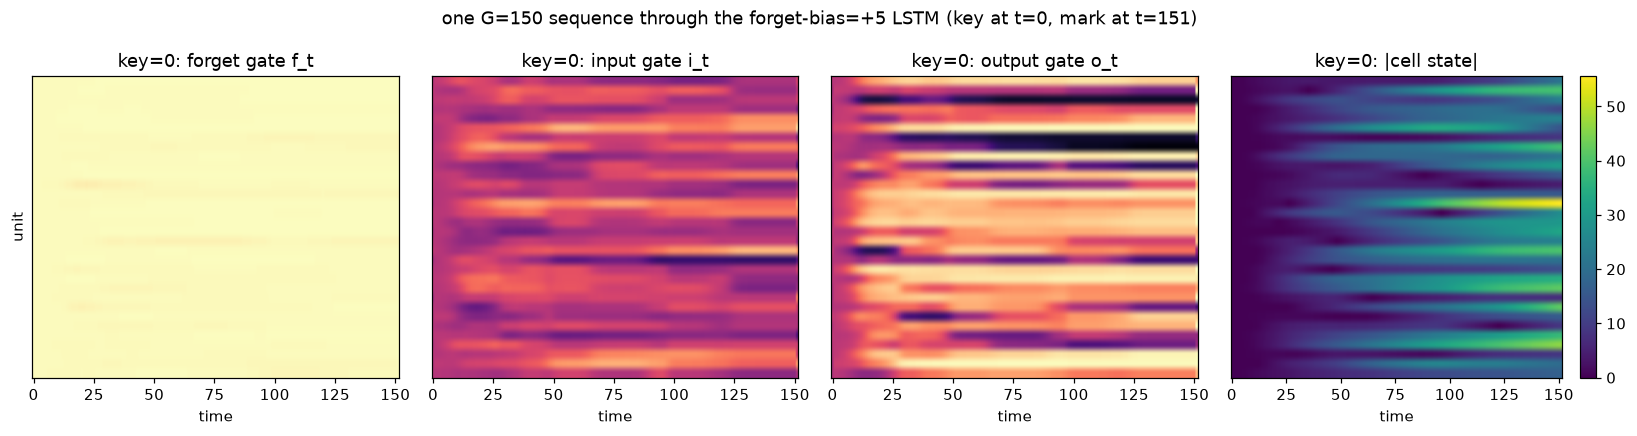

6 most 'conveyor-belt' units (mean f over the runway): [4, 14, 0, 16, 10, 5]
their mean forget value: [0.997, 0.997, 0.997, 0.997, 0.998, 0.998]
prediction at the mark: 0 (target 0, confidence 1.00)


In [7]:
xs_one, key_one = make_batch(150, 1, np.random.default_rng(42))
cache = lstm_hero.forward(xs_one)
T = len(cache)
F = np.stack([c[1][0] for c in cache])
I = np.stack([c[2][0] for c in cache])
O = np.stack([c[3][0] for c in cache])
Cn = np.stack([np.abs(c[5][0]) for c in cache])

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, M, ttl, vmax in ((axes[0], F, "forget gate f_t", 1), (axes[1], I, "input gate i_t", 1),
                         (axes[2], O, "output gate o_t", 1), (axes[3], Cn, "|cell state|", Cn.max())):
    im = ax.imshow(M.T, aspect="auto", cmap="viridis" if vmax > 1 else "magma", vmin=0, vmax=vmax)
    ax.set_xlabel("time"); ax.set_title(f"key={key_one[0]}: {ttl}")
    ax.set_yticks([])
axes[0].set_ylabel("unit")
plt.colorbar(im, ax=axes[3], fraction=0.046)
fig.suptitle(f"one G=150 sequence through the forget-bias=+5 LSTM (key at t=0, mark at t={T - 1})")
fig.tight_layout(); fig.savefig(FIGS / "lstm_gates.png", dpi=140, bbox_inches="tight"); plt.show()

open_units = np.argsort(F[5:-5].mean(0))[-6:]
print("6 most 'conveyor-belt' units (mean f over the runway):", [int(u) for u in open_units])
print("their mean forget value:", [round(float(F[5:-5, u].mean()), 3) for u in open_units])
p1 = lstm_hero.loss_grads(xs_one, key_one)[2]
print(f"prediction at the mark: {int(p1.argmax())} (target {int(key_one[0])}, confidence {float(p1.max()):.2f})")

## 4. Re-running Lab 2.2's two decay experiments on the memory channel

Experiment A (echo, forward): flip the **key** between random keys at position 0 and watch $\|\Delta c_t\|$ / $\|\Delta h_t\|$ travel the 150-step runway. Experiment B (blame, backward): $\left\|\partial L_{final} / \partial c_t\right\|$ and $\partial L/\partial h_t$ per position, on the hero LSTM and on the surviving-at-60 vanilla RNN — three anchors against Lab 2.2's retention-0.74 slopes.

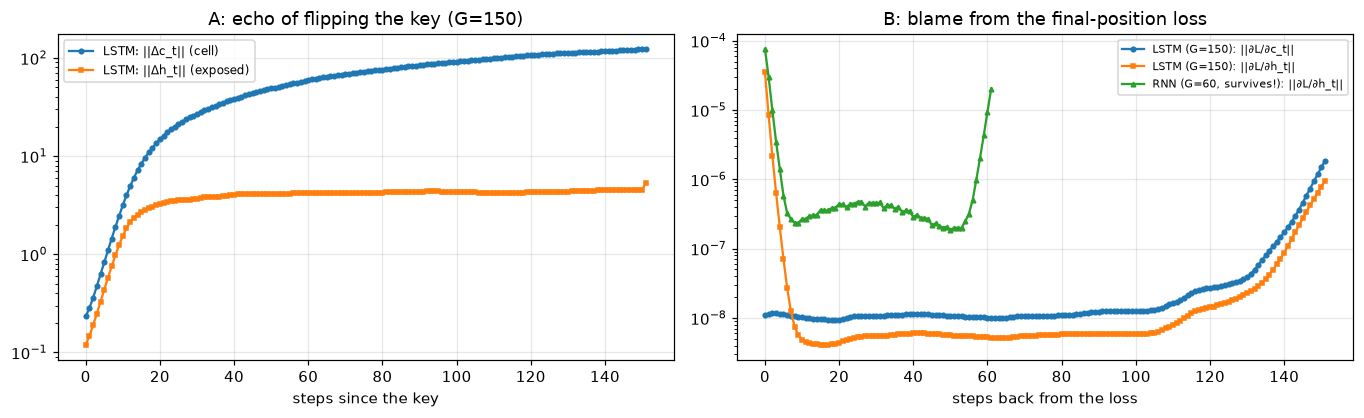

fitted half-lives (steps):              echo | blame
  Lab 2.2 char-RNN on text:             2.3 | 2.3
  LSTM hero cell channel:               n/a | 37.5
  LSTM hero h channel:                  n/a | n/a
  RNN at G=60 (WINNING model):        967.6 | n/a

blame at 30-back vs 5-back: LSTM-c 0.959 | LSTM-h 0.078 | RNN@60 0.77607


In [8]:
def echo_probe(model, G, reps=16, seed=9):
    r = np.random.default_rng(seed)
    dc_list, dh_list = [], []
    for _ in range(reps):
        xs, keys = make_batch(G, 1, r)
        xs2 = xs.copy(); xs2[0, 0] = (xs[0, 0] + r.integers(1, N_KEYS)) % N_KEYS
        if isinstance(model, TaskLSTM):
            c1 = np.stack([c[5][0] for c in model.forward(xs)])
            h1 = np.stack([c[8][0] for c in model.forward(xs)])
            c2 = np.stack([c[5][0] for c in model.forward(xs2)])
            h2 = np.stack([c[8][0] for c in model.forward(xs2)])
            dc_list.append([float(np.linalg.norm(a - b)) for a, b in zip(c1, c2)])
        else:
            h1 = np.stack([hh[0] for hh in model.forward(xs)])
            h2 = np.stack([hh[0] for hh in model.forward(xs2)])
        dh_list.append([float(np.linalg.norm(a - b)) for a, b in zip(h1, h2)])
    return (np.mean(dc_list, axis=0) if isinstance(model, TaskLSTM) else None), np.mean(dh_list, axis=0)

def blame_probe(model, G, n=64, seed=6):
    r = np.random.default_rng(seed)
    xs, keys = make_batch(G, n, r)
    B, T = xs.shape
    if isinstance(model, TaskLSTM):
        cache = model.forward(xs)
        H = model.H
        p = softmax_rows(cache[-1][8] @ model.Wy.T + model.by)
        gy = p.copy(); gy[np.arange(B), keys] -= 1; gy /= B
        dh = gy @ model.Wy
        dc = np.zeros((B, H))
        dhs, dcs = [], []
        d_cat = model.E.shape[1] + H
        for t in reversed(range(T)):
            xh, f, i, o, g, c, c_prev, tanhc, h = cache[t]
            do_ = dh * tanhc
            dc = dc + dh * o * (1 - tanhc ** 2)
            dcs.append(float(np.linalg.norm(dc, axis=1).mean()))
            df, di, dg = dc * c_prev, dc * g, dc * i
            dc_prev = dc * f
            dzf, dzi = df * f * (1 - f), di * i * (1 - i)
            dzo, dzg = do_ * o * (1 - o), dg * (1 - g ** 2)
            dprev = dzf @ model.Wf + dzi @ model.Wi + dzo @ model.Wo + dzg @ model.Wg
            dh = dprev[:, d_cat - H:]
            dhs.append(float(np.linalg.norm(dh, axis=1).mean()))
            dc = dc_prev
        return np.array(dcs[::-1]), np.array(dhs[::-1])
    hs = model.forward(xs)
    p = softmax_rows(hs[-1] @ model.Wy.T + model.by)
    g = p.copy(); g[np.arange(B), keys] -= 1; g /= B
    dh = g @ model.Wy
    dhs = []
    for t in reversed(range(T)):
        da = dh * (1 - hs[t + 1] ** 2)
        dhs.append(float(np.linalg.norm(da, axis=1).mean()))
        dh = da @ model.Wh
    return None, np.array(dhs[::-1])

def fit_halflife(y):
    y = np.asarray(y, float)
    pk = int(np.argmax(y))
    seg = y[pk:]
    ok = seg > 1e-12
    if ok.sum() < 5 or np.unique(np.nonzero(ok)[0]).size < 2:
        return float("nan")
    m, _ = np.polyfit(np.arange(len(seg))[ok], np.log(seg[ok]), 1)
    return -np.log(2) / m if m < 0 else float("inf")

def fmt(v):
    return f"{v:.1f}" if np.isfinite(v) else "n/a"

dc_echo, dh_echo = echo_probe(lstm_hero, 150)
dc_blame, dh_blame = blame_probe(lstm_hero, 150)
_, dhr_echo = echo_probe(rnn60, 60, seed=8)
_, dhr_blame = blame_probe(rnn60, 60)

Tl = len(dc_echo)                                # x-axis for the LSTM (G=150)
Tbl = len(dc_blame)
distB = (Tbl - 1) - np.arange(Tbl)              # blame arrays: position -> distance from loss

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
axes[0].semilogy(dc_echo, "o-", ms=3, lw=1.5, label="LSTM: ||Δc_t|| (cell)")
axes[0].semilogy(dh_echo, "s-", ms=3, lw=1.5, label="LSTM: ||Δh_t|| (exposed)")
axes[0].set_title("A: echo of flipping the key (G=150)")
axes[0].set_xlabel("steps since the key"); axes[0].grid(alpha=.3); axes[0].legend(fontsize=8)

axes[1].semilogy(distB, dc_blame, "o-", ms=3, lw=1.5, label="LSTM (G=150): ||∂L/∂c_t||")
axes[1].semilogy(distB, dh_blame, "s-", ms=3, lw=1.5, label="LSTM (G=150): ||∂L/∂h_t||")
distR = (len(dhr_blame) - 1) - np.arange(len(dhr_blame))
axes[1].semilogy(distR, dhr_blame, "^-", ms=3, lw=1.5, label="RNN (G=60, survives!): ||∂L/∂h_t||")
axes[1].set_title("B: blame from the final-position loss")
axes[1].set_xlabel("steps back from the loss"); axes[1].grid(alpha=.3); axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / "decay_remeasured.png", dpi=140, bbox_inches="tight"); plt.show()

d30, d5 = Tbl - 1 - 30, Tbl - 1 - 5
d30r, d5r = len(dhr_blame) - 1 - 30, len(dhr_blame) - 1 - 5
print("fitted half-lives (steps):              echo | blame")
print(f"  Lab 2.2 char-RNN on text:             2.3 | 2.3")
print(f"  LSTM hero cell channel:               {fmt(fit_halflife(dc_echo))} | {fmt(fit_halflife(dc_blame))}")
print(f"  LSTM hero h channel:                  {fmt(fit_halflife(dh_echo))} | {fmt(fit_halflife(dh_blame))}")
print(f"  RNN at G=60 (WINNING model):        {fmt(fit_halflife(dhr_echo))} | {fmt(fit_halflife(dhr_blame))}")
print(f"\nblame at 30-back vs 5-back: LSTM-c {dc_blame[d30] / dc_blame[d5]:.3f} | LSTM-h {dh_blame[d30] / dh_blame[d5]:.3f} | RNN@60 {dhr_blame[d30r] / dhr_blame[d5r]:.5f}")

## 5. What the gates actually bought

**The mechanism is real and it is the one from §0.** In the winning model: gate units visibly holding $f \approx 0.997$ for a hundred idle steps while $i$ slept and $o$ woke at the mark; the copy at the mark lands with confidence 1.00; and the §4 numbers say it in one row: **blame half-life through the cell channel ≈ 38 steps (vs 2.3 in Lab 2.2's text-RNN); blame retention 30 steps back = 0.96 through $c$ vs 0.08 through $h$** — the cell is the memory, the exposed state is just its readout.

**But the honest arc was two failed priors.** First, the RNN refused to die at G=60 — the 0.74 retention from Lab 2.2 was measured under *text*, where every step is a different transport map; under a constant blank input the RNN can dedicate its entire $W_{hh}$, $E[\mathrm{blank}]$ to one trained slow transport (its §4 blame curve shows it: trained terrain, not geology). Long dependencies fail *in context*, not in the abstract. Second failure: **the mechanism that can hold 150 steps doesn't learn that it can**, from a cold start with loss on one position — `bf=+1` sits at chance for 4,000 clean steps while `bf=+3` and `+5` solve the same task in 1,000. That is the whole "forget bias" lesson of Gers et al. / Greff et al., reproduced by hand: the lever matters more than every architectural detail combined (they found the same ranking in 2015).

**The curriculum was a lottery, and we kept the tickets.** At our scale (H=32, 8 classes, one loss position) staged training sometimes climbed to a clean solve and sometimes stalled anywhere from 0.2–0.7 — three outcomes, same recipe. Above this size the literature's curriculum is dependable; below it, basins decide. We'd rather show you the seam than pretend a knob did more work than it did.

**One optimizer nuance, for the record.** Even a good lever needs signal resolution: the same forget bias that won at batch 128 / lr 1e-3 wobbled to ~0.3 under batch 64 / lr 2e-3 — a per-coordinate Adam step on a thin, noisy gradient estimate. Part of the RNN's surprising short-gap record is optimizer, not architecture: Adam amplifies faint-but-coherent signals by design, and Lab 2.2's measured decay attacked *magnitude*, not *direction*. Attention, next lab, attacks both at once — it reads by content instead of carrying by state.

**Honest ceiling:** a perfectly trained LSTM still reads its history serially and spends gate bandwidth deciding what deserves a slot. Nothing inside lets it *jump to the position that matters*. Retrieval by content — no carriage required — is Lab 2.4's attention.

**Reading:**
1. Hochreiter & Schmidhuber, [*Long Short-Term Memory*](https://www.mitpressjournals.org/doi/10.1162/neco.1997.9.8.1735) (1997) — the carousel, now that we've measured it.
2. Gers, Schmidhuber, Cummins, [*Learning to Forget*](https://direct.mit.edu/neco/article/12/10/2451/2993) (2000) — the forget gate is a late addition, not LSTM v1.
3. Greff et al., [*LSTM: A Search Space Odyssey*](https://arxiv.org/abs/1503.04069) (2015) — variants ablated; forget bias +1 keeps winning.
4. Arjovsky et al., [*Unitary Evolution RNNs*](https://arxiv.org/abs/1511.06464) — copy-task setup incl. the curriculum our hero used.
5. Olah, [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) — the standard picture.

**Next (Lab 2.4):** attention from raw tensors — Q/K/V by hand on a 4-token toy, then causal self-attention on Shakespeare, retrieval instead of carriage.

---

### Reproduce

```bash
cd labs/ml/lm-internals
../mnist-internals/.venv/bin/jupyter lab    # kernel "Python (lm-labs shared)"; open 03_lstms_gates_as_memory_engineering.ipynb
```

Artifacts: `checkpoints/lab23/` (stage-1 grid + curriculum/ablation accuracies) and `figures/lab23/*.png`.

In [9]:
print("grid results:")
for G, name, acc in GRID:
    print(f"  {name:<28} G={G:>3}  acc = {acc:.3f}")
save_ckpt(CKPT, "grid_full", metrics={f"{name}_G{G}": round(acc, 3) for G, name, acc in GRID},
          hero_Wf=lstm_hero.Wf, hero_bf=lstm_hero.bf)
print()
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<14} metrics={e['metrics']}")

grid results:
  RNN H=32                     G= 10  acc = 1.000
  LSTM H=32                    G= 10  acc = 1.000
  RNN H=32                     G= 30  acc = 1.000
  LSTM H=32                    G= 30  acc = 1.000
  RNN H=32                     G= 60  acc = 1.000
  LSTM H=32                    G= 60  acc = 0.086
  RNN H=32                     G=150  acc = 0.152
  LSTM H=32 (naive)            G=150  acc = 0.152
  RNN H=64 (param control)     G=150  acc = 0.238
  LSTM bf=+1 (control @clean budget) G=150  acc = 0.152
  LSTM bf=+3                   G=150  acc = 0.328
  LSTM bf=+5                   G=150  acc = 1.000
  RNN H=32 (kept for §4-§5)    G= 60  acc = 1.000

checkpoints written this lab:
  grid_stage1    metrics={'RNN H=32_G10': 1.0, 'LSTM H=32_G10': 1.0, 'RNN H=32_G30': 1.0, 'LSTM H=32_G30': 1.0, 'RNN H=32_G60': 1.0, 'LSTM H=32_G60': 0.086, 'RNN H=32_G150': 0.152, 'LSTM H=32 (naive)_G150': 0.152, 'RNN H=64 (param control)_G150': 0.238}
  grid_full      metrics={'RNN H=32_G10': 1.0